# 06 · Encoder on all training texts

The same model and code as notebook 03 (XLM-RoBERTa base, 512-token chunks, mean over all chunks at prediction
time), with one change: it is trained on all ~245k texts outside the validation fold instead of the 40k subsample,
for 2 epochs instead of 3. The TF-IDF baseline gained +0.012 from doubling its training texts, so the encoder is
expected to be limited by data as well. Validation texts are still never used in training, so its validation
predictions can feed the stacker of notebook 04.

In [1]:
# Setup: clone/update the repo on Colab/Kaggle, install requirements, resolve paths, get the data
import os, sys, subprocess
REPO_URL = "https://github.com/anna-kryvulia/ucu-ai-hw-generated-text-detection.git"
BRANCH = "main"   # branch with the code you pushed
if "google.colab" in sys.modules or os.path.exists("/kaggle/working"):
    ROOT = "/content/repo" if "google.colab" in sys.modules else "/kaggle/working/repo"
    if not os.path.exists(ROOT):
        subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, ROOT], check=True)
    else:
        subprocess.run(["git", "-C", ROOT, "pull", "-q"], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{ROOT}/requirements.txt"], check=True)
else:
    ROOT = os.path.abspath("..")
sys.path.insert(0, f"{ROOT}/src")

from hwkit import env
from hwkit.download import ensure_data
from hwkit.tracker import Run
P = env.setup(seed=42)
ensure_data(P)

platform: kaggle
    data: /kaggle/input/competitions/ai-generated-text-detection-hw3-ucu-ai-2026
 outputs: /kaggle/working/outputs
   cache: /tmp/hwkit_cache
    repo: /kaggle/working/repo
  device: cuda
data ready at /kaggle/input/competitions/ai-generated-text-detection-hw3-ucu-ai-2026


PosixPath('/kaggle/input/competitions/ai-generated-text-detection-hw3-ucu-ai-2026')

In [2]:
# Imports, config, data with the fixed split from notebook 01
os.environ["TOKENIZERS_PARALLELISM"] = "false"     # the tokenizer runs before DataLoader workers are forked
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging
from huggingface_hub.utils import logging as hub_logging

from hwkit.config import load_config
from hwkit.split import LABELS, load_split, scores
from hwkit.submission import make_submission

# library info messages (the classification layer is new and untrained, download hints); errors still show
hf_logging.set_verbosity_error()
hub_logging.set_verbosity_error()
assert torch.cuda.is_available(), "turn on the GPU (Kaggle: Settings -> Accelerator -> GPU T4 or P100)"
DEV = "cuda"
NOTEBOOK_START = time.time()
cfg = load_config("encoder_xlmr_full")
TC = cfg["train"]
FIG = P.outputs / "figures"
FIG.mkdir(parents=True, exist_ok=True)
METRICS = ["macro_f1_testlike", "macro_f1", "accuracy", "f1_human", "f1_fusion", "f1_ai"]

train = load_split(pd.read_csv(P.data / "train.csv"))
train["domain_lang"] = train["domain"] + " | " + train["lang"]
sub = cfg["data"]["subsample"]
fit = train[train[sub] if sub else train["fold"] != 0].reset_index(drop=True)
val = train[train["fold"] == 0].reset_index(drop=True)
test = pd.read_csv(P.data / "test.csv")
del train
monitor_idx = np.random.default_rng(42).choice(len(val), TC["monitor_size"], replace=False)
run = Run(cfg["name"], cfg, P)
print(f"training: {len(fit)} texts; validation: {len(val)}; test: {len(test)}; GPU: {torch.cuda.get_device_name()}")

run 'encoder_xlmr_full' at /kaggle/working/outputs/runs/encoder_xlmr_full  done: nothing yet
training: 245116 texts; validation: 27236; test: 25000; GPU: Tesla T4


## Tokens and chunks

In [3]:
# Tokenize every text without length limit, then describe how many 510-token chunks the texts need
tok = AutoTokenizer.from_pretrained(cfg["model"]["arch"])
BODY = cfg["model"]["max_len"] - 2            # room left after the start and end tokens

def token_ids(texts, batch=2000):
    """Token ids of each text (without special tokens) as int32 arrays."""
    out = []
    for i in range(0, len(texts), batch):
        enc = tok(list(texts[i:i + batch]), add_special_tokens=False, verbose=False)["input_ids"]
        out += [np.asarray(x, dtype=np.int32) for x in enc]
    return out

def chunk_starts(n):
    """Start positions of the chunks covering a text of n tokens; the last chunk ends exactly at the text's end."""
    if n <= BODY:
        return [0]
    return list(range(0, n - BODY, BODY)) + [n - BODY]

def wrap(x):
    """Add the start and end tokens to a chunk."""
    return np.concatenate([[tok.cls_token_id], x, [tok.sep_token_id]]).astype(np.int64)

t0 = time.time()
ids = {name: token_ids(df["text"].tolist()) for name, df in (("fit", fit), ("val", val), ("test", test))}
for df in (fit, val, test):
    df.drop(columns="text", inplace=True)              # the token ids are all that is needed from here on
print(f"tokenized in {(time.time() - t0) / 60:.1f} min")
pd.DataFrame({name: {"median tokens": np.median([len(x) for x in v]),
                     "share > 510 tokens": np.mean([len(x) > BODY for x in v]),
                     "mean chunks per text": np.mean([len(chunk_starts(len(x))) for x in v]),
                     "max chunks": max(len(chunk_starts(len(x))) for x in v)}
              for name, v in ids.items()}).round(3)

tokenized in 12.6 min


,fit,val,test
median tokens,665.000,659.000,658.000
share > 510 tokens,0.640,0.634,0.615
mean chunks per text,2.067,2.055,2.018
max chunks,39.000,25.000,19.000


In [4]:
# Datasets: one random chunk per training text and epoch; every chunk of every text for prediction
class RandomChunk(Dataset):
    def __init__(self, token_lists, labels):
        self.x, self.y = token_lists, labels
    def __len__(self):
        return len(self.x)
    def __getitem__(self, i):
        x = self.x[i]
        start = int(torch.randint(0, max(len(x) - BODY, 0) + 1, (1,)))    # torch RNG: differs per worker
        return wrap(x[start:start + BODY]), self.y[i]

def collate(batch):
    """Pad the chunks of a batch to the longest one; the attention mask marks real tokens."""
    xs, ys = zip(*batch)
    width = max(len(x) for x in xs)
    input_ids = torch.full((len(xs), width), tok.pad_token_id, dtype=torch.long)
    mask = torch.zeros((len(xs), width), dtype=torch.long)
    for i, x in enumerate(xs):
        input_ids[i, :len(x)] = torch.from_numpy(x)
        mask[i, :len(x)] = 1
    return input_ids, mask, torch.tensor(ys)

@torch.no_grad()
def chunk_probs(token_lists):
    """Class probabilities of every chunk of every text: arrays (text index, chunk position, probabilities)."""
    doc, pos, chunks = [], [], []
    for d, x in enumerate(token_lists):
        for k, s in enumerate(chunk_starts(len(x))):
            doc.append(d)
            pos.append(k)
            chunks.append(x[s:s + BODY])
    order = np.argsort([len(c) for c in chunks], kind="stable")   # similar lengths together: less padding
    loader = DataLoader([(wrap(chunks[i]), 0) for i in order], batch_size=TC["eval_batch_size"],
                        collate_fn=collate, num_workers=2)
    model.eval()
    out = []
    for input_ids, mask, _ in loader:
        with torch.autocast("cuda", dtype=torch.float16):
            logits = model(input_ids=input_ids.to(DEV), attention_mask=mask.to(DEV)).logits
        out.append(torch.softmax(logits.float(), dim=-1).cpu().numpy())
    probs = np.empty((len(chunks), len(LABELS)), dtype=np.float32)
    probs[order] = np.concatenate(out)
    return np.array(doc), np.array(pos), probs

def aggregate(doc, pos, probs, n_texts, how="mean"):
    """Text probabilities: the mean over all chunks, or the first chunk only."""
    if how == "first":
        out = np.zeros((n_texts, probs.shape[1]), dtype=np.float32)
        out[doc[pos == 0]] = probs[pos == 0]
        return out
    out = np.zeros((n_texts, probs.shape[1]), dtype=np.float64)
    np.add.at(out, doc, probs)
    return (out / np.bincount(doc, minlength=n_texts)[:, None]).astype(np.float32)

def to_labels(p):
    return np.array(LABELS)[p.argmax(axis=1)]

## Fine-tuning

AdamW optimizer, learning rate 2e-5 with a linear *warmup* (the rate grows from 0 during the first 10% of steps,
which keeps the first updates from destroying the pretrained weights) and a linear decay to 0. *Mixed precision*
(float16 on the GPU) roughly halves memory and time. After each epoch a fixed sample of 4,000 validation texts is
scored for the learning curve; nothing is selected on it, the model after the last epoch is the final one.
A checkpoint is saved after every epoch, so a restarted session continues from there.

In [5]:
# Model, optimizer, schedule; resume from the last epoch checkpoint if there is one
model = AutoModelForSequenceClassification.from_pretrained(
    cfg["model"]["arch"], num_labels=len(LABELS),
    id2label=dict(enumerate(LABELS)), label2id={c: i for i, c in enumerate(LABELS)}).to(DEV)
label_idx = {c: i for i, c in enumerate(LABELS)}
loader = DataLoader(RandomChunk(ids["fit"], fit["label"].map(label_idx).tolist()), batch_size=TC["batch_size"],
                    shuffle=True, drop_last=True, collate_fn=collate, num_workers=2, pin_memory=True,
                    generator=torch.Generator().manual_seed(42))
steps = len(loader) * TC["epochs"]
no_decay = ("bias", "LayerNorm.weight")                    # usual practice: no weight decay on these
params = [{"params": [p for n, p in model.named_parameters() if not n.endswith(no_decay)],
           "weight_decay": TC["weight_decay"]},
          {"params": [p for n, p in model.named_parameters() if n.endswith(no_decay)], "weight_decay": 0.0}]
opt = torch.optim.AdamW(params, lr=TC["lr"])
sched = get_linear_schedule_with_warmup(opt, int(TC["warmup"] * steps), steps)
scaler = torch.amp.GradScaler("cuda")
start_epoch = 0
if not run.is_done("train") and run.ckpt("last.pt").exists():
    state = torch.load(run.ckpt("last.pt"), map_location="cpu", weights_only=False)
    for obj, key in ((model, "model"), (opt, "opt"), (sched, "sched"), (scaler, "scaler")):
        obj.load_state_dict(state[key])
    start_epoch = state["epoch"]
    del state
print(f"{len(loader)} steps per epoch, {TC['epochs']} epochs; starting at epoch {start_epoch + 1}")

15319 steps per epoch, 2 epochs; starting at epoch 1


In [6]:
# Training loop: one random chunk per text and epoch; learning-curve score on the monitor sample after each epoch
if not run.is_done("train"):
    for epoch in range(start_epoch, TC["epochs"]):
        model.train()
        t0, loss_sum, seen = time.time(), 0.0, 0
        for input_ids, mask, y in loader:
            input_ids, mask, y = input_ids.to(DEV), mask.to(DEV), y.to(DEV)
            with torch.autocast("cuda", dtype=torch.float16):
                logits = model(input_ids=input_ids, attention_mask=mask).logits
            loss = F.cross_entropy(logits.float(), y)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scale = scaler.get_scale()
            scaler.step(opt)                      # skipped when float16 gradients overflowed
            scaler.update()
            if scaler.get_scale() >= scale:       # move the schedule only when the optimizer really stepped
                sched.step()
            loss_sum += loss.item() * len(y)
            seen += len(y)
        mon = val.iloc[monitor_idx]
        p = aggregate(*chunk_probs([ids["val"][i] for i in monitor_idx]), len(mon))
        s = scores(mon["label"], to_labels(p), mon["weight"])
        run.log_epoch(epoch + 1, {"train_loss": loss_sum / seen, "monitor_macro_f1_testlike": s["macro_f1_testlike"],
                                  "monitor_macro_f1": s["macro_f1"], "minutes": (time.time() - t0) / 60})
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "sched": sched.state_dict(),
                    "scaler": scaler.state_dict(), "epoch": epoch + 1}, run.ckpt("last.pt"))
        print(f"epoch {epoch + 1}: loss {loss_sum / seen:.4f}, monitor macro-F1 (test-like) "
              f"{s['macro_f1_testlike']:.4f}, {(time.time() - t0) / 60:.1f} min")
    torch.save({k: v.half() for k, v in model.state_dict().items()}, run.ckpt("model.pt"))   # weights only
    run.ckpt("last.pt").unlink()                  # optimizer state is no longer needed (saves 2 GB of output)
    run.mark_done("train")
else:
    model.load_state_dict({k: v.float() for k, v in torch.load(run.ckpt("model.pt"), map_location="cpu", weights_only=True).items()})
run.history.round(4)

epoch 1: loss 0.2802, monitor macro-F1 (test-like) 0.9082, 149.8 min
epoch 2: loss 0.1743, monitor macro-F1 (test-like) 0.9375, 148.9 min


,epoch,time,train_loss,monitor_macro_f1_testlike,monitor_macro_f1,minutes
0,1,2026-11-20 16:25:35,0.2802,0.9082,0.9044,149.7408
1,2,2026-11-20 18:54:30,0.1743,0.9375,0.9358,148.8475


**Findings.** Each epoch over all ~245k texts takes 2.5 hours on a T4. After the first epoch the monitor score (0.908)
is already above the 40k model after three epochs (0.898); the second epoch, with the learning rate decaying to 0,
adds another +0.03.

## Full validation: first chunk only vs all chunks, compared with the baseline

In [7]:
# Chunk probabilities for all validation and test texts (stored, so a restarted session does not recompute them)
chunk_file = {name: run.dir / "predictions" / f"chunks_{name}.npz" for name in ("val", "test")}
if not run.is_done("predict"):
    t0 = time.time()
    for name in ("val", "test"):
        doc, pos, probs = chunk_probs(ids[name])
        np.savez_compressed(chunk_file[name], doc=doc, pos=pos, probs=probs)
    run.mark_done("predict")
    print(f"{(time.time() - t0) / 60:.1f} min")
chunks = {name: dict(np.load(f)) for name, f in chunk_file.items()}
prob = {(name, how): aggregate(c["doc"], c["pos"], c["probs"], len(ids[name]), how)
        for name, c in chunks.items() for how in ("first", "mean")}

15.2 min


In [8]:
# Validation scores: TF-IDF baseline and XLM-R on 40k (same split) vs XLM-R on all training texts
base_dir = P.repo / "results" / "runs" / "baseline_tfidf"
base40 = pd.read_csv(base_dir / "search.csv").iloc[0]
base80 = json.loads((base_dir / "metrics.json").read_text())["val"]
enc40 = json.loads((P.repo / "results" / "runs" / "encoder_xlmr" / "metrics.json").read_text())["val"]
k = f"{len(fit) // 1000}k"
enc = {how: scores(val["label"], to_labels(prob[("val", how)]), val["weight"]) for how in ("first", "mean")}
run.log_metrics("val", {"aggregation": "mean", **enc["mean"]})
run.log_metrics("val_first_chunk", {"aggregation": "first", **enc["first"]})
pd.DataFrame([{"model": "TF-IDF + LogReg, 40k texts", **base40[METRICS].to_dict()},
              {"model": "TF-IDF + LogReg, 80k texts", **{m: base80[m] for m in METRICS}},
              {"model": "XLM-R, mean of all chunks, 40k", **{m: enc40[m] for m in METRICS}},
              {"model": f"XLM-R, first 512 tokens, {k}", **{m: enc["first"][m] for m in METRICS}},
              {"model": f"XLM-R, mean of all chunks, {k}", **{m: enc["mean"][m] for m in METRICS}}]).round(4)

,model,macro_f1_testlike,macro_f1,accuracy,f1_human,f1_fusion,f1_ai
0,"TF-IDF + LogReg, 40k texts",0.8538,0.8598,0.8816,0.7906,0.8068,0.9819
1,"TF-IDF + LogReg, 80k texts",0.8657,0.8717,0.8917,0.8081,0.8219,0.9850
2,"XLM-R, mean of all chunks, 40k",0.8985,0.8975,0.9158,0.8287,0.8739,0.9900
3,"XLM-R, first 512 tokens, 245k",0.8967,0.8935,0.9114,0.8342,0.8538,0.9926
4,"XLM-R, mean of all chunks, 245k",0.9362,0.9361,0.9473,0.8946,0.9182,0.9955


**Findings.** Six times more training texts give +0.038 test-like macro-F1 (0.898 → 0.936) with the same model and
settings, the largest single gain so far. Human F1 rises from 0.829 to 0.895 and fusion from 0.874 to 0.918. Reading
all chunks still matters as much as before: +0.040 over the first 512 tokens.

In [9]:
# Macro-F1 by number of chunks per text: where reading the whole text should matter most
n_chunks = np.bincount(chunks["val"]["doc"], minlength=len(val))
bucket = pd.cut(n_chunks, [0, 1, 2, 4, 100], labels=["1 chunk", "2 chunks", "3-4 chunks", "5+ chunks"])
rows = []
for b in bucket.categories:
    m = np.asarray(bucket == b)
    rows.append({"length": b, "texts": int(m.sum()),
                 **{f"macro_f1 {how}": f1_score(val["label"][m], to_labels(prob[("val", how)][m]), labels=LABELS,
                                                average="macro", zero_division=0) for how in ("first", "mean")}})
pd.DataFrame(rows).round(4)

,length,texts,macro_f1 first,macro_f1 mean
0,1 chunk,9958,0.9474,0.9474
1,2 chunks,10787,0.8984,0.9612
2,3-4 chunks,5416,0.8157,0.8974
3,5+ chunks,1075,0.7048,0.8081


**Findings.** Every length bucket improves, but the pattern stays: texts with 5+ chunks are the hardest (0.81), and the
other chunks add +0.06 to +0.10 over the first one for texts longer than one chunk.

In [10]:
# Per-class precision, recall and F1 on validation (mean of all chunks, unweighted)
pred_val = to_labels(prob[("val", "mean")])
print(classification_report(val["label"], pred_val, labels=LABELS, digits=3))

              precision    recall  f1-score   support

       human      0.918     0.872     0.895      6674
      fusion      0.904     0.932     0.918      8367
          ai      0.992     0.999     0.996     12195

    accuracy                          0.947     27236
   macro avg      0.938     0.934     0.936     27236
weighted avg      0.947     0.947     0.947     27236



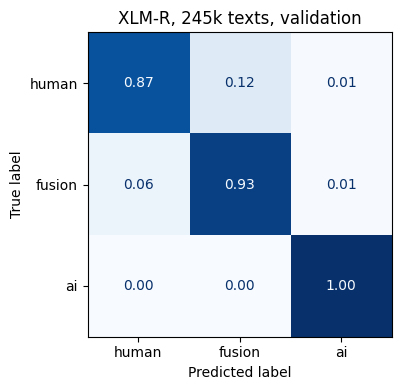

In [11]:
# Figure: confusion matrix on validation, each row normalized to 1 (share of true class predicted as each class)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(val["label"], pred_val, labels=LABELS, normalize="true",
                                        values_format=".2f", cmap="Blues", colorbar=False, ax=ax)
ax.set_title(f"XLM-R, {len(fit) // 1000}k texts, validation")
plt.tight_layout()
plt.savefig(FIG / f"{cfg['name']}_confusion.png", dpi=120)
plt.show()

In [12]:
# Macro-F1 and accuracy per domain on validation (macro-F1 over the classes present in that domain)
res = val.assign(pred=pred_val)
pd.DataFrame({dl: {"texts": len(g), "accuracy": (g["label"] == g["pred"]).mean(),
                   "macro_f1": f1_score(g["label"], g["pred"], labels=sorted(g["label"].unique()),
                                        average="macro", zero_division=0)}
              for dl, g in res.groupby("domain_lang")}).T.round(3).sort_values("macro_f1")

,texts,accuracy,macro_f1
arxiv_papers | en-EN,1429.0,0.971,0.632
gutenberg | en-EN,692.0,0.977,0.792
gutenberg | de-DE,43.0,0.953,0.845
blog_authorship_corpus | en-EN,4053.0,0.902,0.893
euro_court_cases | en-EN,2759.0,0.916,0.895
bundestag | de-DE,5234.0,0.930,0.924
house_of_commons | en-EN,3186.0,0.949,0.935
student_essays | en-EN,5411.0,0.972,0.967
cnn_news | en-EN,4429.0,0.986,0.983


**Findings.** All domains except arxiv improve; arxiv stays at 0.63 macro-F1 despite 97% accuracy, because its few
human and fusion texts are confused. The stacker of notebook 04 fixed most of this for the 40k model, so the same
should be checked with this model.

In [13]:
# Class probabilities for validation and test (kept for ensembles) and the Kaggle submission
cols = [f"s_{c}" for c in LABELS]
for name, df, keep in (("val", val, ["id", "label"]), ("test", test, ["id"])):
    for how, suffix in (("mean", ""), ("first", "_first")):
        pd.concat([df[keep], pd.DataFrame(prob[(name, how)], columns=cols)], axis=1).to_csv(
            run.pred_path(name + suffix), index=False)
sub = make_submission(test["id"], to_labels(prob[("test", "mean")]), P.outputs / "submissions" / f"{cfg['name']}.csv",
                      P.data)

submission saved: /kaggle/working/outputs/submissions/encoder_xlmr_full.csv  (25000 rows)
label
ai        0.516
fusion    0.250
human     0.234


In [14]:
# Distinct warnings logged in this session (should be empty), total time
print(f"total: {(time.time() - NOTEBOOK_START) / 60:.1f} min")
env.warnings_summary(P)

total: 327.1 min


[]